# Evaluación de los estimadores de f0

Notebook del frente C. Lee los CSV de resultados **por nota** (`analisis/resultados/notas_<implementacion>_<conjunto>.csv`, formato de `docs/contratos.md`, sección 5.5) y calcula las métricas de la tabla del README.

**Estado actual:** solo hay resultados de la cadena provisional (`implementacion = librosa`, método `yin`) sobre el subconjunto de NSynth. Cuando los frentes A y B generen sus CSV con el mismo formato, este notebook los incluye sin cambios: basta con volver a ejecutarlo.

Para regenerar los datos de entrada, desde la raíz del repositorio:

```bash
analisis/.venv/bin/python analisis/evaluacion/procesar_librosa.py --conjunto nsynth \
    --indice datos/indice_nsynth.csv --audio datos/nsynth/48k --N 2048 4096 8192 16384
analisis/.venv/bin/python analisis/evaluacion/metricas.py \
    --tramos analisis/resultados/tramos/librosa_nsynth.csv --referencias datos/indice_nsynth.csv
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comun import DATOS, RESULTADOS, cargar_parametros
from estilo import ANCHO_COLUMNA, ANCHO_PAGINA, aplicar_estilo, guardar
from metricas import CATEGORIAS, ERRORES_ARMONICOS, clasificar, conteo_categorias, tabla_metricas

aplicar_estilo()
p = cargar_parametros()
N0 = p["tramo"]["N"]
pd.set_option("display.precision", 1)

## Datos

In [2]:
notas = pd.concat([pd.read_csv(f) for f in sorted(RESULTADOS.glob("notas_*.csv"))], ignore_index=True)
indice = pd.read_csv(DATOS / "indice_nsynth.csv")
nsynth = notas[notas["conjunto"] == "nsynth"].merge(
    indice[["archivo", "familia", "instrumento_nsynth", "midi", "velocidad"]], on="archivo", how="left")
nsynth["categoria"] = nsynth["cents_error"].map(clasificar)
print(notas.groupby(["implementacion", "conjunto", "metodo", "N"]).size().rename("notas").to_string())
print()
print(indice.groupby("familia").agg(notas=("archivo", "size"), instrumentos=("instrumento_nsynth", "nunique"),
                                   midi_min=("midi", "min"), midi_max=("midi", "max")).to_string())

implementacion  conjunto  metodo  N    
librosa         nsynth    yin     2048     839
                                  4096     839
                                  8192     839
                                  16384    839

         notas  instrumentos  midi_min  midi_max
familia                                         
bass       157             3        23        63
guitar     408             7        23        76
string     274             6        24        76


## Métricas por tamaño de tramo

Los porcentajes usan todas las notas como denominador: una nota sin estimación cuenta como fallo. `error_abs_medio_cents` incluye los errores de octava; `…_nota_correcta_cents` solo las notas a ±50 cents.

In [3]:
tabla_metricas(notas)

,implementacion,conjunto,metodo,N,notas,con_estimacion_pct,acierto_afinacion_pct,acierto_nota_pct,errores_octava_armonico_pct,error_abs_medio_cents,error_abs_medio_nota_correcta_cents,error_abs_mediana_nota_correcta_cents
0,librosa,nsynth,yin,2048,839.0,97.5,44.9,79.6,8.6,197.8,5.8,4.4
1,librosa,nsynth,yin,4096,839.0,98.8,64.5,92.4,5.2,78.2,4.8,2.8
2,librosa,nsynth,yin,8192,839.0,99.2,66.4,92.7,5.0,75.0,4.5,2.1
3,librosa,nsynth,yin,16384,839.0,99.9,65.3,92.7,4.8,104.3,4.7,1.9


## Métricas por familia (N = tamaño por defecto)

In [4]:
tabla_metricas(nsynth[nsynth["N"] == N0], por=["implementacion", "metodo", "N", "familia"])

,implementacion,metodo,N,familia,notas,con_estimacion_pct,acierto_afinacion_pct,acierto_nota_pct,errores_octava_armonico_pct,error_abs_medio_cents,error_abs_medio_nota_correcta_cents,error_abs_mediana_nota_correcta_cents
0,librosa,yin,4096,bass,157.0,99.4,87.9,93.6,5.7,72.2,2.8,2.4
1,librosa,yin,4096,guitar,408.0,97.8,53.4,95.1,1.5,31.9,6.1,4.3
2,librosa,yin,4096,string,274.0,100.0,67.5,87.6,10.6,149.0,3.8,2.4


## Figura: error en cents frente a la nota

Eje vertical en escala *symlog*: lineal entre ±50 cents y logarítmica fuera, para ver a la vez los errores finos y los de octava o armónico (líneas punteadas).

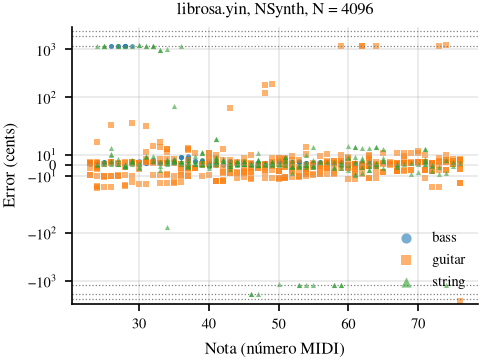

In [5]:
fig, ax = plt.subplots(figsize=(ANCHO_COLUMNA, 2.4))
d = nsynth[(nsynth["N"] == N0) & nsynth["cents_error"].notna()]
marcas = {"bass": "o", "guitar": "s", "string": "^"}
for fam, g in d.groupby("familia"):
    ax.scatter(g["midi"], g["cents_error"], s=6, alpha=0.6, marker=marcas.get(fam, "o"), label=fam, linewidths=0)
for nominal in ERRORES_ARMONICOS:
    ax.axhline(nominal, color="0.5", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=50)
ax.set_ylim(-3000, 3000)
ax.set_xlabel("Nota (número MIDI)")
ax.set_ylabel("Error (cents)")
ax.set_title(f"librosa.yin, NSynth, N = {N0}")
ax.legend(loc="lower right", markerscale=2, frameon=False)
guardar(fig, "nsynth_librosa_error_vs_midi")
plt.show()

## Figura: categorías de error según N

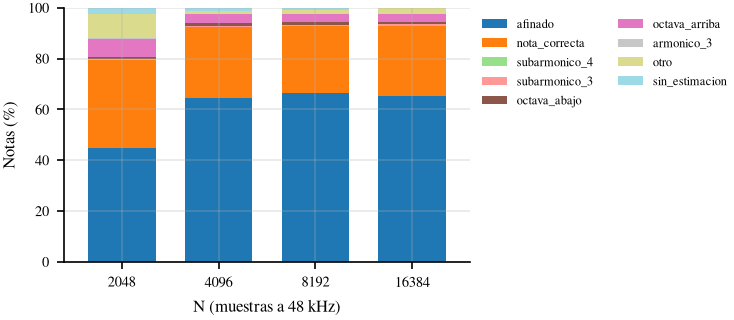

categoria,afinado,nota_correcta,subarmonico_4,subarmonico_3,octava_abajo,octava_arriba,armonico_3,otro,sin_estimacion
N,,,,,,,,,
2048,44.9,34.7,0.1,0.0,1.1,6.8,0.6,9.3,2.5
4096,64.5,27.9,0.0,0.4,1.2,3.7,0.0,1.2,1.2
8192,66.4,26.3,0.0,0.4,1.3,3.3,0.0,1.4,0.8
16384,65.3,27.4,0.0,0.8,0.8,3.1,0.0,2.4,0.1


In [6]:
cat = conteo_categorias(nsynth, por=["N"])
fig, ax = plt.subplots(figsize=(ANCHO_COLUMNA, 2.2))
cat.plot(kind="bar", stacked=True, ax=ax, width=0.7, colormap="tab20")
ax.set_xlabel("N (muestras a 48 kHz)")
ax.set_ylabel("Notas (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=6, ncol=2, frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left")
guardar(fig, "nsynth_librosa_categorias_vs_N")
plt.show()
cat.round(1)

## Notas con mayor error (N = tamaño por defecto)

In [7]:
(nsynth[nsynth["N"] == N0]
 .assign(abs_cents=lambda x: x["cents_error"].abs())
 .sort_values("abs_cents", ascending=False)
 [["archivo", "familia", "midi", "f_ref_hz", "f0_hz", "cents_error", "categoria", "tramos_activos"]]
 .head(15))

,archivo,familia,midi,f_ref_hz,f0_hz,cents_error,categoria,tramos_activos
1817,guitar_acoustic_030-076-050,guitar,76,659.3,149.1,-2573.3,otro,5
2569,string_acoustic_014-047-050,string,47,123.5,41.7,-1878.4,subarmonico_3,158
2565,string_acoustic_014-046-100,string,46,116.5,39.4,-1875.8,subarmonico_3,168
2561,string_acoustic_014-046-050,string,46,116.5,39.4,-1875.8,subarmonico_3,168
2625,string_acoustic_014-059-050,string,59,246.9,122.3,-1216.4,octava_abajo,129
2629,string_acoustic_014-059-075,string,59,246.9,122.3,-1216.4,octava_abajo,129
2621,string_acoustic_014-058-100,string,58,233.1,115.5,-1215.6,octava_abajo,138
2617,string_acoustic_014-058-050,string,58,233.1,115.5,-1215.6,octava_abajo,138
1809,guitar_acoustic_030-074-050,guitar,74,587.3,1183.0,1212.3,octava_arriba,19
2473,string_acoustic_014-030-050,string,30,46.2,93.1,1210.8,octava_arriba,188


## ¿Error del estimador o desafinación de las muestras?

Las etiquetas de NSynth son el número MIDI **nominal**: no garantizan que la muestra esté afinada a ±1 cent. Si un instrumento tiene un desfase sistemático, todas sus notas lo comparten. Aquí se mira, entre las notas con la nota correcta (|c| ≤ 50) y N = 8192, la mediana y la dispersión del error por instrumento.

In [8]:
d = nsynth[(nsynth["N"] == 8192) & (nsynth["cents_error"].abs() <= 50)]
por_inst = d.groupby(["familia", "instrumento_nsynth"])["cents_error"].agg(
    notas="count", mediana_cents="median", desv_cents="std",
    afinado_pct=lambda x: 100 * (x.abs() <= p["nota"]["afinado_cents"]).mean())
residuo = d["cents_error"] - d.groupby("instrumento_nsynth")["cents_error"].transform("median")
print(f"Afinado (|c| <= 5) sin corregir: {100 * (d['cents_error'].abs() <= 5).mean():.1f} %")
print(f"Afinado tras restar la mediana de cada instrumento: {100 * (residuo.abs() <= 5).mean():.1f} %")
por_inst.round(2)

Afinado (|c| <= 5) sin corregir: 71.6 %
Afinado tras restar la mediana de cada instrumento: 76.7 %


notas  mediana_cents  desv_cents  afinado_pct
familia instrumento_nsynth                                                  
bass    bass_electronic_018       48            1.3         1.0        100.0
        bass_electronic_025       49            1.5         0.8        100.0
        bass_electronic_027       50            1.2         1.0        100.0
guitar  guitar_acoustic_010       66            3.2         4.6         56.1
        guitar_acoustic_014       76           -6.4         5.1         47.4
        guitar_acoustic_015       57            3.5        10.1         57.9
        guitar_acoustic_021       66          -12.0         5.2          9.1
        guitar_acoustic_030       16            1.5        13.9         68.8
        guitar_electronic_022     54           -4.1         6.5         63.0
        guitar_electronic_028     55            1.3         0.5        100.0
string  string_acoustic_012       45            0.5         1.9         95.6
        string_acoustic_014       30            4.3        11.4         43.3
        string_acoustic_056       56            2.2         4.3         82.1
        string_acoustic_057       28           -1.1         4.5         67.9
        string_acoustic_071       41            0.4         2.4         92.7
        string_acoustic_080       41            0.9         2.0         95.1

/tmp/ipykernel_619899/2144800131.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos, vert=False, showfliers=False, widths=0.6)


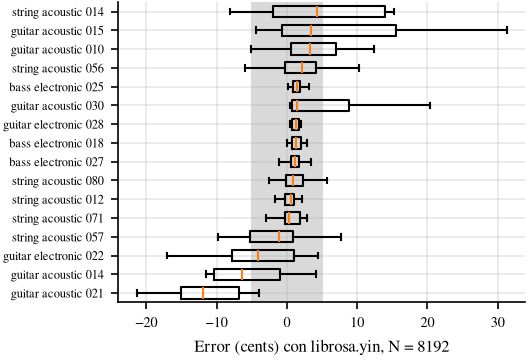

In [9]:
fig, ax = plt.subplots(figsize=(ANCHO_COLUMNA, 2.6))
orden = por_inst.sort_values("mediana_cents").index.get_level_values("instrumento_nsynth")
datos = [d.loc[d["instrumento_nsynth"] == i, "cents_error"] for i in orden]
ax.boxplot(datos, vert=False, showfliers=False, widths=0.6)
ax.set_yticks(range(1, len(orden) + 1), [i.replace("_", " ") for i in orden], fontsize=6)
ax.axvspan(-p["nota"]["afinado_cents"], p["nota"]["afinado_cents"], color="0.85", zorder=0)
ax.set_xlabel("Error (cents) con librosa.yin, N = 8192")
guardar(fig, "nsynth_librosa_error_por_instrumento")
plt.show()

## Observaciones

_Para escribir por el grupo después de revisar las tablas y figuras: qué falla, en qué notas y por qué._